In [1]:
# ==============================================================================
# GENERACIÓN DE RASTER DE DISTANCIA EUCLIDIANA A VÍAS EN PYTHON (ANACONDA)
# ==============================================================================

import geopandas as gpd
import numpy as np
import rasterio
from rasterio.transform import from_origin
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt
import matplotlib.pyplot as plt

In [5]:
# 1. CARGA Y PROYECCIÓN DE CAPAS VECTORIALES (MAGNA-SIRGAS CTM12 / EPSG:9377)
# ------------------------------------------------------------------------------

path_aoi = "D:/Maestria_Geomatica/Semestre_IV/Tesis_Python/Datos/SHP/AOI_25_09_19_EPSG9377.shp"
path_vias = "D:/Maestria_Geomatica/Semestre_IV/Tesis_Python/Datos/SHP/vias_totales_EPSG9377_26_09_11.shp"


In [7]:
# Leer shapefiles
aoi_gdf = gpd.read_file(path_aoi)
vias_gdf = gpd.read_file(path_vias)

# Eliminar dimensión Z si existe y reproyectar al CRS oficial (EPSG: 9377)
aoi_proj = aoi_gdf.to_crs(epsg=9377)
vias_proj = vias_gdf.to_crs(epsg=9377)

# ------------------------------------------------------------------------------
# 2. DEFINICIÓN DE LA GRILLA RASTER PLANTILLA
# ------------------------------------------------------------------------------

# Resolución espacial deseada (30 metros por píxel)
pixel_size = 30.0

# Obtener los límites geográficos (Bounding Box) del AOI
minx, miny, maxx, maxy = aoi_proj.total_bounds

# Calcular el número de filas y columnas del raster
width = int(np.ceil((maxx - minx) / pixel_size))
height = int(np.ceil((maxy - miny) / pixel_size))

In [9]:
# Transformación afín para mapear coordenadas geográficas con la matriz NumPy
transform = from_origin(minx, maxy, pixel_size, pixel_size)

Raster exportado exitosamente en: D:/Maestria_Geomatica/Semestre_IV/Tesis_Python/Datos/TIFF/distancia_vias_py_m_26_09_11.tif


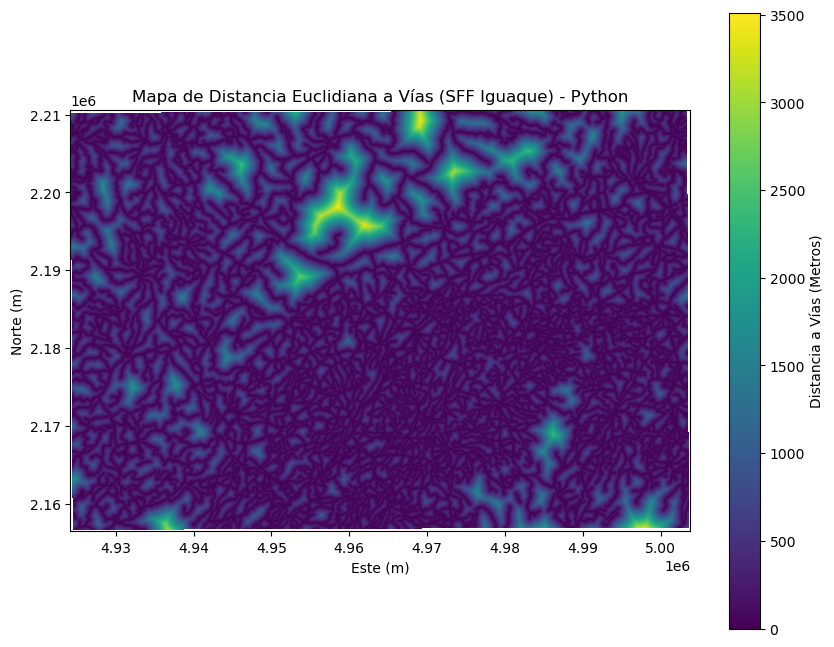

In [13]:
# ------------------------------------------------------------------------------
# 3. RASTERIZACIÓN Y CÁLCULO DE DISTANCIA EUCLIDIANA CONTINUA
# ------------------------------------------------------------------------------

# A. Rasterizar las líneas de vías (píxeles con vía = 1, resto = 0)
vias_shapes = [(geom, 1) for geom in vias_proj.geometry]
vias_raster = rasterize(
    shapes=vias_shapes,
    out_shape=(height, width),
    transform=transform,
    fill=0,
    dtype=np.uint8
)

# B. Transformada de Distancia Euclidiana (SciPy)
# distance_transform_edt calcula la distancia en "píxeles" a la celda no-cero más cercana.
# Multiplicamos por pixel_size (30 m) para obtener la distancia real en METROS.
dist_matrix_m = distance_transform_edt(vias_raster == 0) * pixel_size

# C. Rasterizar la máscara del AOI para enmascarar fuera del límite del Santuario
aoi_shapes = [(geom, 1) for geom in aoi_proj.geometry]
aoi_mask = rasterize(
    shapes=aoi_shapes,
    out_shape=(height, width),
    transform=transform,
    fill=0,
    dtype=np.uint8
)

# Aplicar máscara (asignar NaN fuera del área de estudio)
dist_matrix_m = np.where(aoi_mask == 1, dist_matrix_m, np.nan)

# ------------------------------------------------------------------------------
# 4. EXPORTAR EL RASTER A GEOTIFF Y VISUALIZAR
# ------------------------------------------------------------------------------

output_geotiff = "D:/Maestria_Geomatica/Semestre_IV/Tesis_Python/Datos/TIFF/distancia_vias_py_m_26_09_11.tif"

metadata = {
    'driver': 'GTiff',
    'height': height,
    'width': width,
    'count': 1,
    'dtype': 'float32',
    'crs': 'EPSG:9377',
    'transform': transform,
    'nodata': np.nan
}

with rasterio.open(output_geotiff, 'w', **metadata) as dst:
    dst.write(dist_matrix_m.astype('float32'), 1)

print(f"Raster exportado exitosamente en: {output_geotiff}")

# Graficar
plt.figure(figsize=(10, 8))
plt.imshow(dist_matrix_m, cmap='viridis', extent=[minx, maxx, miny, maxy])
plt.colorbar(label='Distancia a Vías (Metros)')
plt.title('Mapa de Distancia Euclidiana a Vías (SFF Iguaque) - Python')
plt.xlabel('Este (m)')
plt.ylabel('Norte (m)')
plt.show()